# Phase 1: data quality

What this notebook checks, in order: the universe, how many filings we have and of what kind, coverage per firm and
per month (holes), whether the API agrees with the raw archive, how timestamps map to trading sessions, how well the
PDF text extraction works, and whether prices are complete.

**Test period:** the tables below count documents and price rows up to December 2025. Counting is not evaluating:
no return, volatility or score from the test period (2024-07 onwards) is computed or plotted anywhere in this notebook.

All logic lives in `cac40_mood.data`; the cells only call it and plot.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from cac40_mood import plotting
from cac40_mood.config import FIGURES_DIR, RAW_DIR
from cac40_mood.data import dila_archive, quality
from cac40_mood.data import prices as prices_module
from cac40_mood.data.build import (
    FILINGS_ALL_PATH,
    FILINGS_PATH,
    PRICES_PATH,
    SESSIONS_PATH,
    TEXTS_PATH,
)
from cac40_mood.data.filings import FEED_GAP_END, FEED_GAP_START
from cac40_mood.data.sessions import trading_sessions
from cac40_mood.data.universe import load_universe

plotting.apply_style()
pd.set_option("display.max_columns", 30, "display.width", 220, "display.max_colwidth", 60)

universe = load_universe()
filings_all = pd.read_parquet(FILINGS_ALL_PATH)  # every row, translations included
filings = pd.read_parquet(FILINGS_PATH)  # one row per document
texts = pd.read_parquet(TEXTS_PATH)
prices = pd.read_parquet(PRICES_PATH)
sessions = trading_sessions(prices[prices["firm_id"] == prices_module.INDEX_ID])
to_score = filings[~filings["is_admin"]]

## 1. Universe
37 current CAC 40 members (Euronext composition of 2026-11-11) that file with the French OAM. Firms with an
`index_entry_date` joined the index recently; using today's members for the whole sample is the survivorship /
selection bias we report (they are the firms that did well enough to be in the index now).

URW stays in these tables but is **left out of the main analysis** (36 firms): Yahoo has its prices only from
April 2023 (DECISIONS #29, section 8 below).

In [2]:
print(len(universe), "firms;", (universe["isin_previous"] != "").sum(), "with a pre-split ISIN")
joined = universe[universe["index_entry_date"] >= "2019-01-01"]
joined[["firm_id", "name", "index_entry_date", "note"]].sort_values("index_entry_date")

37 firms; 3 with a pre-split ISIN


,firm_id,name,index_entry_date,note
32,HO,Thales,2019-06-24,
14,ERF,Eurofins Scientific,2021-09-17,New ISIN after the 10-for-1 share split in November 2020
0,AC,Accor,2024-03-18,Left the index 2020-09-21 and re-entered 2024-03-18
5,BVI,Bureau Veritas,2024-12-23,
15,ENX,Euronext,2025-09-22,
11,FGR,Eiffage,2025-12-22,


## 2. How many filings, and of what kind

In [3]:
funnel = pd.Series(
    {
        "rows from both sources (one per document and language)": len(filings_all),
        "English translations removed": int(filings_all["is_translation"].sum()),
        "documents kept": len(filings),
        "admin documents (counted, not scored)": int(filings["is_admin"].sum()),
        "documents to score": len(to_score),
        "  of which French": int((to_score["lang"] == "fr").sum()),
        "  of which English only": int((to_score["lang"] == "en").sum()),
    },
    name="count",
)
funnel.to_frame()

,count
rows from both sources (one per document and language),24768
English translations removed,9963
documents kept,14805
"admin documents (counted, not scored)",7582
documents to score,7223
of which French,6470
of which English only,753


In [4]:
quality.class_summary(filings, sessions)

,documents,admin,french,english,after_close,intraday,non_trading_day,pre_open
doc_class,,,,,,,,
inside_information,6142,False,5538,604,0.401,0.192,0.011,0.395
voting_rights,2810,True,2701,109,0.598,0.370,0.005,0.027
own_shares,2264,True,1854,410,0.664,0.262,0.006,0.068
threshold_crossing,1680,True,1680,0,0.038,0.930,0.000,0.032
availability_notice,641,True,596,45,0.601,0.276,0.016,0.108
periodic_report,627,False,551,76,0.341,0.493,0.010,0.156
quarterly_information,336,False,293,43,0.402,0.128,0.009,0.461
debt_terms,187,True,25,162,0.283,0.701,0.005,0.011
takeover,58,False,39,19,0.500,0.224,0.017,0.259


## 3. Coverage per firm and year (documents to score)
A sane table has no empty cell and no firm-year far below its neighbours, except 2020 (see section 4).

In [5]:
firm_year = quality.firm_year_counts(to_score)
firm_year

year,2019,2020,2021,2022,2023,2024,2025,total
firm_id,,,,,,,,
AC,33,10,16,13,18,15,17,122
ACA,56,26,66,38,54,57,70,367
AI,50,37,57,53,57,47,41,342
BN,12,17,31,20,17,16,19,132
BNP,13,5,12,18,16,16,30,110
BVI,21,14,24,16,14,26,21,136
CA,34,20,20,18,20,17,39,168
CAP,24,20,16,12,12,15,25,124
CS,23,12,18,21,15,15,13,117


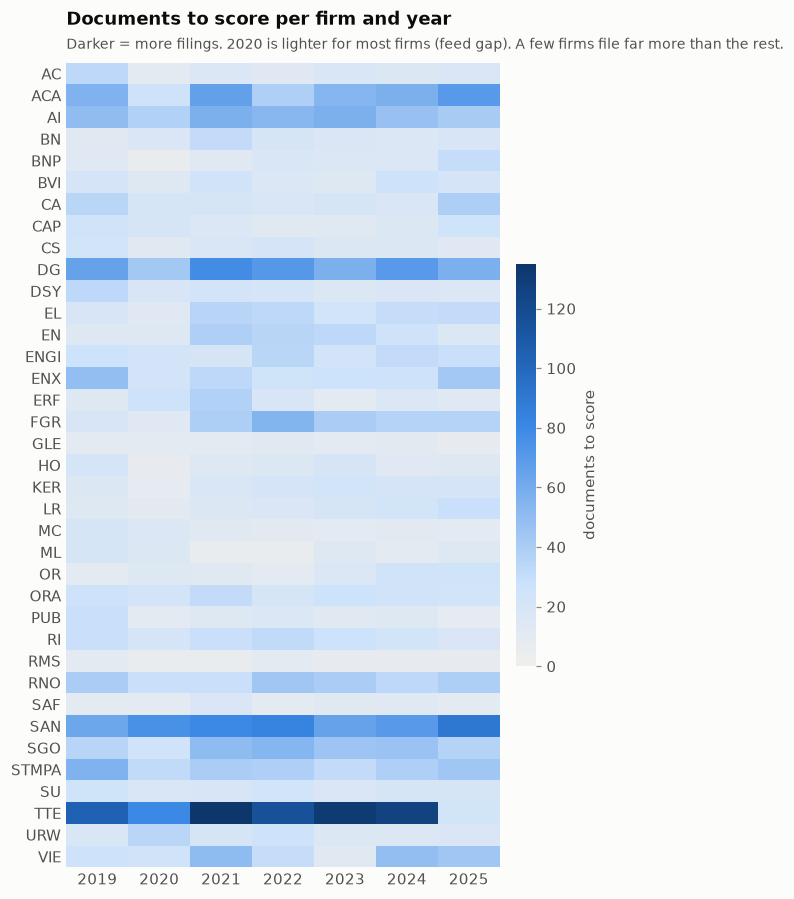

In [6]:
years = [column for column in firm_year.columns if column != "total"]
figure, axes = plt.subplots(figsize=(6.2, 9.5))
image = axes.imshow(firm_year[years].to_numpy(), cmap=plotting.SEQUENTIAL, aspect="auto", vmin=0)
axes.set_xticks(range(len(years)), years)
axes.set_yticks(range(len(firm_year)), firm_year.index)
axes.grid(False)
axes.tick_params(length=0)
for spine in axes.spines.values():
    spine.set_visible(False)
bar = figure.colorbar(image, ax=axes, shrink=0.5, pad=0.03)
bar.outline.set_visible(False)
bar.set_label("documents to score")
plotting.titled(
    axes,
    "Documents to score per firm and year",
    "Darker = more filings. 2020 is lighter for most firms (feed gap). A few firms file far more than the rest.",
)
plotting.save(figure, FIGURES_DIR / "01_firm_year_heatmap.png")
plt.show()

## 4. Coverage per month: the spring-2020 hole
The official feed is nearly empty from 5 March to 15 June 2020 (first COVID lockdown). The hole is in the source
itself: the API, the archive bundles and the raw folder tree all show it.

Decision (#28): the window is excluded from estimation and evaluation and treated as **missing data, never as
"no news"**. `sessions.parquet` carries a `feed_observed` flag per trading day for that purpose.

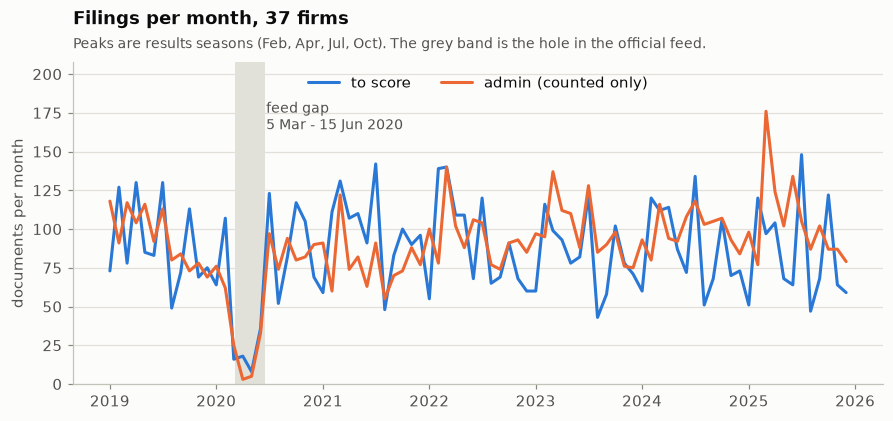

month,2020-01,2020-02,2020-03,2020-04,2020-05,2020-06,2020-07,2020-08
kind,,,,,,,,
admin,76,62,25,3,5,33,97,74
to_score,64,107,16,18,8,36,123,52


In [7]:
monthly = quality.monthly_counts(filings)
month_start = monthly.index.to_timestamp()
figure, axes = plt.subplots(figsize=(9.5, 3.8))
axes.axvspan(
    pd.Timestamp(FEED_GAP_START), pd.Timestamp(FEED_GAP_END), color=plotting.GRID, linewidth=0
)
axes.plot(month_start, monthly["to_score"], color=plotting.SERIES[0], label="to score")
axes.plot(month_start, monthly["admin"], color=plotting.SERIES[1], label="admin (counted only)")
axes.annotate(
    "feed gap\n5 Mar - 15 Jun 2020",
    xy=(pd.Timestamp("2020-06-20"), monthly.to_numpy().max() * 1.04),
    color=plotting.INK_SECONDARY,
    fontsize=9,
    va="top",
)
axes.set_ylim(0, monthly.to_numpy().max() * 1.18)
axes.set_ylabel("documents per month")
axes.legend(loc="upper center", ncols=2)
plotting.titled(
    axes,
    "Filings per month, 37 firms",
    "Peaks are results seasons (Feb, Apr, Jul, Oct). The grey band is the hole in the official feed.",
)
plotting.save(figure, FIGURES_DIR / "01_filings_per_month.png")
plt.show()
monthly.loc["2020-01":"2020-08"].T

In [8]:
gap = filings[filings["in_feed_gap"]]
normal = filings[(filings["ts_paris"] >= "2019-03-05") & (filings["ts_paris"] < "2019-06-16")]
print(f"documents inside the gap window: {len(gap)} (to score: {(~gap['is_admin']).sum()})")
print(
    f"same calendar window one year earlier: {len(normal)} (to score: {(~normal['is_admin']).sum()})"
)
calendar = pd.read_parquet(SESSIONS_PATH)
print("trading days flagged as feed not observed:", int((~calendar["feed_observed"]).sum()))

documents inside the gap window: 43 (to score: 29)
same calendar window one year earlier: 722 (to score: 337)
trading days flagged as feed not observed: 70


## 5. Does the API agree with the raw archive?
For January 2019 - June 2020 we have both sources. `archive_only` documents are missing from the API;
`api_only` documents are missing from the bundles we downloaded.

In [9]:
manifest = dila_archive.read_manifest(RAW_DIR / "dila" / "manifest.jsonl")
errors = [name for name, entry in manifest.items() if "error" in entry]
print(
    f"{len(manifest)} bundles processed, {len(errors)} with errors, "
    f"{sum(entry.get('bytes', 0) for entry in manifest.values()) / 1e9:.1f} GB read"
)
overlap = quality.source_overlap(filings_all, "2019-01-01", "2020-07-01")
overlap.loc["ALL"] = overlap.sum()
overlap

3001 bundles processed, 0 with errors, 15.6 GB read


origin,both,api_only,archive_only
month,,,
2019-01,294,0,0
2019-02,362,0,0
2019-03,293,0,7
2019-04,373,0,11
2019-05,320,0,3
2019-06,290,0,0
2019-07,406,0,7
2019-08,201,0,7
2019-09,234,0,22


## 6. Timestamps and trading sessions
The event time is the **latest** of the feed's timestamps, in Paris time. A filing before 09:00 counts for that
session, one between 09:00 and 17:30 too (flagged intraday), anything later goes to the next trading session.

In [10]:
pd.Series(quality.timestamp_rule_effect(to_score), name="documents to score").to_frame()

,documents to score
documents,7223
timestamps_disagree,1631
disagree_by_more_than_a_day,128
moved_to_a_later_session_side,30


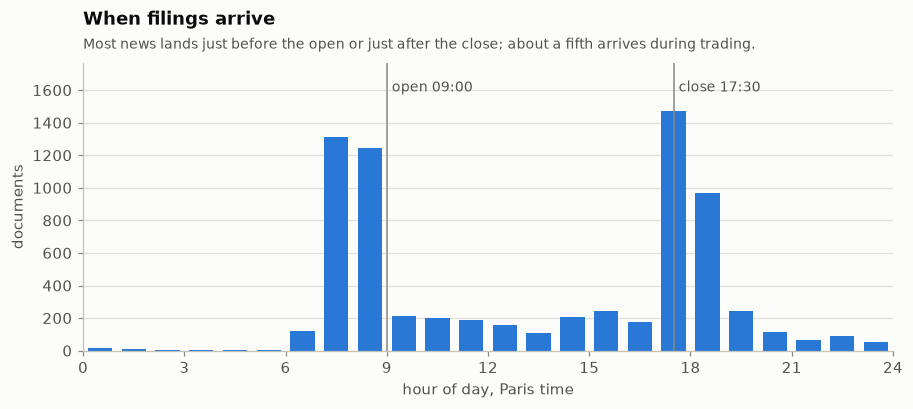

,share
timing,
after_close,0.398
pre_open,0.375
intraday,0.217
non_trading_day,0.011


In [11]:
hours = to_score["ts_paris"].dt.hour.value_counts().reindex(range(24), fill_value=0)
figure, axes = plt.subplots(figsize=(9.5, 3.4))
axes.bar(hours.index + 0.5, hours.to_numpy(), width=0.72, color=plotting.SERIES[0])
for clock, label in [(9.0, "open 09:00"), (17.5, "close 17:30")]:
    axes.axvline(clock, color=plotting.INK_MUTED, linewidth=1)
    axes.text(clock + 0.15, hours.max() * 1.08, label, color=plotting.INK_SECONDARY, fontsize=9)
axes.set_xticks(range(0, 25, 3))
axes.set_xlim(0, 24)
axes.set_ylim(0, hours.max() * 1.2)
axes.set_xlabel("hour of day, Paris time")
axes.set_ylabel("documents")
plotting.titled(
    axes,
    "When filings arrive",
    "Most news lands just before the open or just after the close; about a fifth arrives during trading.",
)
plotting.save(figure, FIGURES_DIR / "01_filing_hour.png")
plt.show()
quality.timing_category(to_score, sessions).value_counts(normalize=True).round(3).to_frame("share")

One real filing per case (picked by rule from train/validation, see `quality.alignment_examples`):

In [12]:
quality.alignment_examples(filings, sessions)

,case,firm,title,ts_amf (feed),ts_market (feed),ts_paris (used),event_session,intraday
0,before the open,AI,Informations privilégiées / Autres communiqués,2021-11-04T07:45:00+00:00,2021-11-04T07:45:00+00:00,Thu 2021-11-04 08:45,Thu 2021-11-04,False
1,during trading hours,SAN,Présentation à l’ECTRIMS 2021 de nouvelles donné,2021-10-13T07:00:00+00:00,2021-10-13T07:00:00+00:00,Wed 2021-10-13 09:00,Wed 2021-10-13,True
2,after the close,VIE,Informations privilégiées / Autres communiqués,2021-11-08T17:45:00+00:00,2021-11-08T17:45:00+00:00,Mon 2021-11-08 18:45,Tue 2021-11-09,False
3,Friday after the close,TTE,Informations privilégiées / Autres communiqués,2021-05-28T16:03:00+00:00,2021-05-28T16:03:00+00:00,Fri 2021-05-28 18:03,Mon 2021-05-31,False
4,weekend,ENGI,ENGIE entre en négociations exclusives avec Bouy,2021-11-05T23:50:08+00:00,2021-11-05T23:49:38+00:00,Sat 2021-11-06 00:50,Mon 2021-11-08,False
5,exchange holiday on a weekday,SAN,Communiqué de presse: Sanofi annonce le retrait,2023-04-10T20:15:00+00:00,2023-04-10T20:15:00+00:00,Mon 2023-04-10 22:15,Tue 2023-04-11,False
6,"deposited intraday, released after the close",BVI,Rapport financier semestriel,2021-07-29T08:15:45+00:00,2021-07-29T15:45:00+00:00,Thu 2021-07-29 17:45,Fri 2021-07-30,False
7,summer time (UTC+2),VIE,Communiqués publiés en période d'offre publique,2021-07-20T17:49:00+00:00,2021-07-20T17:49:00+00:00,Tue 2021-07-20 19:49,Wed 2021-07-21,False


In [13]:
no_session = filings["event_session"].isna().sum()
print("documents without an event session:", no_session, "(filed after the last session of 2025)")
filings.groupby("split", dropna=False).agg(
    documents=("doc_id", "size"), to_score=("is_admin", lambda admin: int((~admin).sum()))
)

documents without an event session: 0 (filed after the last session of 2025)


,documents,to_score
split,,
test,3386,1516
train,8081,4141
val,3338,1566


## 7. PDF text extraction
Target from the plan: at least 95% of the documents to score have usable text.
`empty` = fewer than 200 characters (scanned image), `garbled` = mostly digits and symbols,
`not_pdf` / `missing_file` / `unreadable` = no text could be read.

In [14]:
text_quality = quality.text_quality_summary(filings, texts)
text_quality

text_quality,empty,garbled,missing_file,not_pdf,ok,unreadable,usable_share
doc_class,,,,,,,
governance,0,0,0,0,42,0,1.0000
inside_information,32,18,0,1,6086,5,0.9909
other,5,0,1,0,12,0,0.6667
periodic_report,9,1,0,151,466,0,0.7432
quarterly_information,0,0,2,0,333,1,0.9911
takeover,1,0,0,0,57,0,0.9828
ALL,47,19,3,152,6996,6,0.9686


In [15]:
ok = texts[texts["text_quality"] == "ok"]
print(
    "characters per usable document:",
    ok["text_chars"].describe(percentiles=[0.1, 0.5, 0.9]).round(0).to_dict(),
)
print(
    "documents longer than the 15 pages we read:",
    int((texts["n_pages"] > texts["pages_read"]).sum()),
)
sample = to_score.merge(ok, on="doc_id").query("split == 'train'").sample(3, random_state=1)
for row in sample.itertuples():
    print(
        f"\n--- {row.firm_id} | {row.ts_paris:%Y-%m-%d %H:%M} | {row.title[:70]}\n{row.text[:300]}"
    )

characters per usable document: {'count': 6996.0, 'mean': 12541.0, 'std': 14779.0, 'min': 276.0, '10%': 2080.0, '50%': 5769.0, '90%': 37716.0, 'max': 283820.0}
documents longer than the 15 pages we read: 1018



--- DG | 2020-10-01 08:30 | VINCI signe un accord pour le contrat de PPP d’une autoroute au Kenya
Ce communiqué de presse est un document d’information officiel du groupe VINCI.
CONTACT PRESSE
Service de presse VINCI
Tél. : +33 (0)1 47 16 31 82
media.relations@vinci.com
Rueil-Malmaison, le 1er octobre 2020
VINCI signe un accord pour le contrat de PPP d’une autoroute au Kenya
• Premier partenaria

--- TTE | 2022-10-18 18:12 | Informations privilégiées / Autres communiqués
COMMUNIQUÉ DE PRESSE
Qatar : TotalEnergies annonce le démarrage d’Al Kharsaah
(800 MWc), l’une des plus grandes centrales solaires du
Moyen-Orient
Paris, Doha, 18 octobre 2022 – La centrale solaire d’Al Kharsaah, développée par
TotalEnergies et ses partenaires QatarEnergy et Marubeni, a été inauguré

--- TTE | 2021-05-26 08:33 | Informations privilégiées / Autres communiqués
Communiqué de Presse
Augmentation de capital réservée aux salariés
du Groupe Total en 2021
Paris, 26 mai 2021 – Conformément à sa politique en fa

## 8. Prices
Only completeness is checked here; no return or volatility is computed.

In [16]:
coverage = prices_module.missing_sessions(prices, sessions)
print(len(sessions), "trading sessions from", sessions[0].date(), "to", sessions[-1].date())
print("price rows that break an OHLC sanity rule:", len(prices_module.price_problems(prices)))
coverage[(coverage["n_missing"] > 0) | (coverage["first_day"] > sessions[0])]

2048 trading sessions from 2018-01-02 to 2025-12-31
price rows that break an OHLC sanity rule: 0


,firm_id,first_day,n_days,n_missing
36,URW,2023-04-14,694,0
